In [26]:
import igl
import meshplot as mp
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
import matplotlib.tri as mtri
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.collections import PolyCollection 
import ipywidgets as widgets
from IPython.display import clear_output, display
import time
import threading
from typing import Tuple
from typing import List
%matplotlib widget

In [27]:



def vec2(x: float, y: float) -> np.ndarray:
    '''
    Creates (2,) ndarray
    '''
    return np.array([x, y], dtype=np.float64)


def hat(p: np.ndarray) -> np.ndarray:
    '''
    Rotates 2d vector by pi/2 counterclockwise
    '''
    return vec2(-p[1], p[0])

def compute_triangle_areas(V: np.ndarray, T: np.ndarray) -> np.ndarray:
    '''
    Computes area of each triangle in V, T mesh
    '''
    E = len(T) # no of triangles/elements
    A = np.zeros(E, dtype=np.float64)
    for e in range(E):
        # indecies of vertecies of current triangle
        i, j, k = T[e, :]   
        # coordinates of vertices
        xi, yi = V[i, :]
        xj, yj = V[j, :]
        xk, yk = V[k, :]
        # distances
        dx1 = xk - xj
        dy1 = yk - yj
        dx2 = xi - xj
        dy2 = yi - yj
        # area of current element
        A[e] =  (dx1*dy2 - dx2*dy1 ) / 2.0
    return A


def make_beam_mesh(width: int, height: int, shape: Tuple[int, int]) -> Tuple[np.ndarray, np.ndarray]:
    '''
    Creates a simple rectangular V, T mesh
    '''
    # mesh is centered around (0, 0)
    x0 = -width/2.0
    y0 = -height/2.0
    I, J = shape #resolution
    # distances between cells
    dx = width/float(I)
    dy = height/float(J)

    V = np.zeros(((I + 1)*(J + 1), 2), np.float64)
    # vecrorized double loop
    iy, ix = np.meshgrid(np.arange(J + 1), np.arange(I + 1), indexing='ij')
    V[:, 0] = x0 + ix.ravel()*dx
    V[:, 1] = y0 + iy.ravel()*dy
    
    T = np.zeros((2*I*J,3),dtype=np.int32)
    for j in range(J):
        for i in range(I):
            k00 = (i  ) + (j  )*(I+1)
            k01 = (i+1) + (j  )*(I+1)
            k10 = (i  ) + (j+1)*(I+1)
            k11 = (i+1) + (j+1)*(I+1)
            e = 2*(i + j*I)
            if (i+j+1)%2:
                T[e,  :] = (k00,k01,k11)
                T[e+1,:] = (k00,k11,k10)
            else:
                T[e,  :] = (k10,k00,k01)
                T[e+1,:] = (k10,k01,k11)  
    return V, T

class MeshInfo:
    def __init__(self, V: np.ndarray, T: np.ndarray):
        """
        Initialize object
        """
        self.A = compute_triangle_areas(V, T)
        if np.any(np.where(self.A<=0)):
            raise ValueError('Triangle with negative orientation exist.')
        # bd[e] stores barycenter of e-th element
        self.bc = igl.barycenter(V, T)
        # stores unique edges of mesh (doesn't repeat common edges)
        self.E = igl.edges(T)
        # each row corresponds to a triangle
        # each entry in the row gives the index of the neighboring triangle that shares corresponding edge
        # if edge is on the boundary (i.e. no neighbpur) the entry is set to -1
        self.TT, _ = igl.triangle_triangle_adjacency(T)
        # VT - 1D array with indecies of all triangles adjacent to all vertices, concatenated together
        # NI - 1D array of length num_vertices + 1, where NI[i] and NI[i+1]
        #       give the start and end indices in VT for the triangles adjacent to vertex i
        self.VT, self.NI = igl.vertex_triangle_adjacency(T, len(V))
        # VV[i] stores indecies of adjacent vertecies to i-th vertex
        self.VV = igl.adjacency_list(T)
        # Store V, and T matrices
        self.V = V
        self.T = T
        mask = np.zeros(len(V),dtype=np.int32)
        # setting one for boundary vertecies
        mask[igl.boundary_loop(T)] = 1
        self.boundary_vertex = mask
        
    def get_triangles_of_vertex(self, i: int) -> np.ndarray:
        """
        Returns all triangles that share i-th vertex
        """
        start = self.NI[i]
        end = self.NI[i+1]
        return self.VT[ start:end]
    
    def get_triangles_of_triangle(self, t: int) -> np.ndarray:
        """
        Returns adjacent triangles to t-th triangle
        """
        return self.TT[t]
    
    def get_triangle_center(self, t: int) -> float:
        """
        Barycenter of triangle t
        """
        return self.bc[t]
    
    def get_vertices_of_vertex(self, i: int) -> np.ndarray:
        '''
        Returns vertices adjacent to vertex i
        '''
        return self.VV[i]
    
    def get_triangle_area(self, t: int) -> float:
        """
        Returns area of triangle t
        """
        return self.A[t]
    
    def get_edge_vector_of_triangle(self, t: int, e: int) -> Tuple[np.ndarray, np.ndarray]:
        """
        Returns: edge vector and coordinates of midpoint for edge e of triangle t
        """
        i = self.T[t,e]
        j = self.T[t,(e+1)%3]
        vi = self.V[i,:].flatten()
        vj = self.V[j,:].flatten()
        u = (vj-vi).flatten()
        return u, (vi+vj)/2


    def get_outward_normal_of_triangle(self, t: int, e: int) -> Tuple[np.ndarray, np.ndarray]:
        '''
        Returns: 
        n - unit outward vector
        m - midpoint of edge e of triangle t
        '''
        u, m = self.get_edge_vector_of_triangle(t,e)
        n = -hat(u)/np.linalg.norm(u)
        return n, m
    
    def get_triangle_triangle_segment(self, t: int, e: int) -> Tuple[np.ndarray, np.ndarray]:
        '''
        Computes a vector between two barycenters
        Returns:
        - vector from triangle t to its neighbor across the edge e
        - midpoint of the segment connecting two barycenters
        '''
        n = self.TT[t,e]
        if n>0:
            ct = self.bc[t].flatten()
            cn = self.bc[n].flatten()
            return cn-ct, (cn+ct)/2
        # If no neighbor across the edge then return None, None
        return None, None    

    def get_opposing_triangle(self, t: int, v: int) -> int:
        '''
        input:
            t - index of triangle
            v - index of edge within triangle (0, 1, 2)
        returns:
            index of neighboring triangle
        '''
        e = (v+1)%3
        return self.TT[t,e]
    
    def is_boundary_vertex(self, v: int) -> bool:
        '''
        Checks whether given vertex lies on boundary
        '''
        if self.boundary_vertex[v]==1:
            return True
        return False




def get_cyclic_permuation(v: int, triangle:np.ndarray) -> np.ndarray:
    '''
    Permutes indexes within triangle array in the way that
    vertex v jumps in front
    '''
    i = triangle[0]
    j = triangle[1]
    k = triangle[2]
    if i==v:
        return np.array([i, j, k])
    if j==v:
        return np.array([j, k, i])
    if k==v:
        return np.array([k, i, j])
    return np.array([-1, -1, -1])

def get_ccw_triangle_order(v: int, T: np.ndarray) -> np.ndarray:
    '''
    Orders set of triangles having a common vertex v in ccw order
    input:
    v - vertex index
    T - (n, 3) array containing n triangles all sharing vertex v
    returns: array of triangle indices ordered ccw around v
    '''
    for t in range(len(T)):
        T[t,:] = get_cyclic_permuation(v, T[t,:])    
    if len(T) == 1:
        ccw_order = np.array([0], dtype=np.int32).flatten()
    else:
        ccw_order = []
        next_order = -np.ones((len(T), ), dtype=np.int32)
        prev_order = -np.ones((len(T), ), dtype=np.int32)
        for s in range(len(T)):
            A = T[s,:]
            for t in range(len(T)):
                B = T[t,:]
                if A[2]==B[1]:
                    next_order[s] = t
                if A[1]==B[2]:
                    prev_order[s] = t
        if np.any(prev_order<0):
            i = np.where(prev_order<0)[0]
            while i>=0:
                ccw_order.append(i)
                i = next_order[i]
        else:
            i = 0
            ccw_order.append(i)
            i = next_order[i]
            while i>0:
                ccw_order.append(i)
                i = next_order[i]            
        ccw_order = np.array(ccw_order, dtype=np.int32).flatten()
    return ccw_order
    
class VertexControlVolume:
    def __init__(self, v: int, info: MeshInfo):
        self.info = info
        self.v = v
        self.c = info.V[v,:].flatten()
        # triangles that get 
        self.labels = info.get_triangles_of_vertex(v)
        K = len(self.labels)
        self.K = K     # no of adjacent triangles
        self.boundary = info.is_boundary_vertex(v)
        T = info.T[self.labels,:]

        for t in range(len(T)):
            T[t,:] = get_cyclic_permuation(v, T[t,:])

        self.Lij = np.zeros(( K, ), dtype=np.float64 )
        self.Lik = np.zeros(( K, ), dtype=np.float64 )
        self.Nij = np.zeros(( K, 2), dtype=np.float64 )
        self.Nik = np.zeros(( K, 2), dtype=np.float64 )
        self.Sij = np.zeros(( K, 2), dtype=np.float64 )
        self.Sik = np.zeros(( K, 2), dtype=np.float64 )
        self.P = np.zeros(( K, 2), dtype=np.float64 )
        self.A = np.sum(info.A[self.labels])/3.0
        for e in range(K):
            i, j, k = T[e, :]
            
            pi = info.V[i,:]
            pj = info.V[j,:]
            pk = info.V[k,:]
            
            Eij = (pj-pi)
            Lij = np.linalg.norm(Eij)
            Nij = -hat(Eij)/Lij
            
            Eik = (pk-pi)
            Lik = np.linalg.norm(Eik)
            Nik = hat(Eik)/Lik
        
            self.Lij[e] = Lij/2
            self.Lik[e] = Lik/2
            self.Nij[e,:] = Nij
            self.Nik[e,:] = Nik
            self.Sij[e,:] = Eij/2
            self.Sik[e,:] = Eik/2
            self.P[e,:] = (pi+pj+pk)/3
# Parameters structure
class Parameters:
    
    def __init__(self, material='default'):
        library = { 'cartilage':(0.69e6, 0.018, 1000),
               'cortical bone': (16.16e9, 0.33, 1600),
               'cancellous bone': (452e6, 0.3, 1600),
               'rubber': (0.01e9, 0.48, 1050),
               'concrete': (30e9, 0.20, 2320),
               'copper': (125e9, 0.35, 8900),
               'steel': (210e9, 0.31, 7800),
               'aluminium': (72e9, 0.34, 2700),
               'glass': ( 50e9,  0.18, 2190),
               'default': (10e5,0.3,1000)}
        E, nu, rho = library[material]
        self.material_name = material
        self.E = E              # Young Modulus
        self.nu = nu            # Poisson ratio
        self.rho = rho          # Mass density
        self.lambda_ =  (E*nu) / ((1+nu)*(1-2*nu))  # Lame 1st
        self.mu_     =  E/(2*(1+nu))                # Lame 2nd



### Solver (nope)

In [ ]:
class Solver:
    def __init__(self, material: Parameters, width: int=6, height: int=2, resolution: Tuple[int, int]=(12, 6)):
        '''
        Initializing mesh at time 0, and all important parameters
        '''
        # store arguments in object:
        self.material_name = material.material_name
        self.material = material
        self.lamb = material.lambda_
        self.mu = material.mu_
        self.rho = material.rho
        self.width = width
        self.height = height
        self.resolution = resolution
        # creating a mesh
        Vinit, T = make_beam_mesh(width, height, resolution)
        self.Vinit = Vinit
        self.T = T
        self.nV = len(Vinit)
        self.nT = len(T)
        # setting an external and traction forces (0 by default, can be changed using method)
        self.g = 0
        self.traction = vec2(0, 0)
        self.info = MeshInfo(Vinit, T)
        nV = len(Vinit)
        self.CVs = [VertexControlVolume(v, self.info) for v in range(nV)]
        # initially x_t is set to none until simulate method isn't run
        self.x_t = None
    
    def _compute_P(self, V:np.ndarray) -> np.ndarray:
        '''
        Computes deformation gradient for each triangle given
        current vertex positions V
        '''
 
        P = np.zeros((self.nT, 2, 2))
        for e in range(self.nT):
            
            i, j, k = self.T[e]   # get vertex indecies
            pi = V[i, :]        # get vertex positions
            pj = V[j, :]        # -----||-----
            pk = V[k, :]        #------||-----
            
            pi0 = self.Vinit[i, :]      # initial mesh triangle positions (material coordinates)
            pj0 = self.Vinit[j, :]
            pk0 = self.Vinit[k, :]

            gij = pj - pi       # get displacement vectors
            gik = pk - pi

            gij0 = pj0 - pi0
            gik0 = pk0 - pi0

            D = np.stack((gij, gik)).T      
            D0 = np.stack((gij0, gik0)).T
            # print(f'D = \n{D}\n D0=\n{D0}')
            F = np.matmul(D, np.linalg.inv(D0))
            # print(f'F = \n{F}')          
            E = 0.5*(np.matmul(F.T, F) - np.eye(2))
            # print(f'E = \n{E}')
            S = self.lamb*np.trace(E)*np.eye(2) + 2*self.mu*E
            # print(f'S = \n{S}')
            J = np.matmul(np.linalg.inv(D0), D.T)
            if np.linalg.det(J) <= 0:
                print(f"Inverted triangle detected at element {e}")

            P[e, :, :] = np.matmul(F, S)
            # print(f'P = \n{P[e]}')
        return P
    def _compute_elastic(self) -> np.ndarray:
        f_elastic = np.zeros((self.nV, 2))
        P = self._compute_P(self.V_cur)
        for v_idx in range(self.nV):
            cv = self.CVs[v_idx]
            for e_local in range(cv.K):
                e_global = cv.labels[e_local]
                f_elastic[v_idx] += -0.5*(P[e_global]@cv.Nij[e_local]*cv.Lij[e_local] + P[e_global]@cv.Nik[e_local]*cv.Lik[e_local])
        return f_elastic

    def _compute_body(self) -> np.ndarray:
        f_body = np.zeros((self.nV, 2))
        for v_idx in range(self.nV):
            mass = self.rho * self.CVs[v_idx].A
            f_body[v_idx, 1] = mass * self.g
        return f_body
    
    def _compute_traction(self) -> np.ndarray:
        f_traction = np.zeros((self.nV, 2))
        for v_idx in range(self.nV):
            if np.isin(v_idx, self.right_indices):
                f_traction[v_idx] = self.traction
        return f_traction

    def simulate(self, t_max: float=None, dt: float=None, nt: int=None) -> np.ndarray:
        '''
        Performs a simulation loop over each timestep
        '''
        if t_max == None and dt != None and nt != None:
            t_max = nt*dt
        elif dt == None and t_max != None and nt != None:
            dt = t_max/nt
        elif nt == None and t_max != None and dt != None:
            nt = int(t_max/dt)
        else:
            raise ValueError('You need to choose at least two parameters among t_max, dt, nt')

        t_idxs = np.linspace(0, t_max, nt)
        
        # initializing matrices
        x_t = np.zeros((nt, self.nV, 2))  # Positions of vertices for different times
        v_t = np.zeros((nt, self.nV, 2))  # Velocities --||--
        x_t[0, :, :] = np.copy(self.Vinit)          # setting initial mesh
        # simulation loop:
        self.right_indices = np.where(self.Vinit[:, 0] > self.width/2 - 1e-03)[0] # indexes of right boundary
        self.left_indices = np.where(self.Vinit[:, 0] < -self.width/2 + 1e-03)[0]
        print(f'Left boundary indices: {self.left_indices}\nRight boundary indices: {self.right_indices}')
        for t_idx in range(nt - 1):
            if t_idx%10:
                print(f'Progress: {t_idx}/{nt}, t={t_idxs[t_idx]:.1f}\r', end='', flush=True)
            
            self.V_cur = np.copy(x_t[t_idx])
            f_e = self._compute_elastic()
            f_b = self._compute_body()
            f_t = self._compute_traction()
            f_tot = f_e + f_b + f_t

            for v_idx in range(self.nV):
                # velocity update
                
                if v_idx in self.left_indices:
                    x_t[t_idx + 1, v_idx] = self.Vinit[v_idx]
                    v_t[t_idx + 1, v_idx] = 0.0 
                else:
                    # velocity update
                    mass = self.rho*self.CVs[v_idx].A
                    v_local = v_t[t_idx, v_idx] + dt/mass * f_tot[v_idx]
                    v_t[t_idx + 1, v_idx] = v_local
                    x_local = x_t[t_idx, v_idx] + dt * v_t[t_idx + 1, v_idx]
                    x_t[t_idx + 1, v_idx] = x_local                
        print(f'time step: {nt}/{nt}, t={t_idxs[nt - 1]:.1f}\nFinished')
        self.x_t = x_t
        return x_t
    def set_gravity(self, g: float=0.0):
        self.g = g
    def set_traction(self, x=0, y=0):
        self.traction = vec2(x, y)/self.resolution[1]    # normalized to the number of nodes in y direction

    def plot_initial_vs_final(self):
        plt.figure()
        plt.triplot(self.Vinit[:, 0], self.Vinit[:, 1], self.T, color='gray', linestyle='--', label='initial')
        plt.triplot(self.x_t[-1, :, 0], self.x_t[-1, :, 1], self.T, color='red', label='final')
        plt.legend()
        plt.axis('equal')
        plt.show()
    
    def plot_frame(self, frame: int):
        plt.triplot(self.x_t[frame, :,0], self.x_t[frame, :,1], self.T)
        plt.show()

    def animate(self, size=(10, 6)):
        def animate(t_idx):
            ax.clear()
            ax.triplot(self.x_t[t_idx, :, 0], self.x_t[t_idx, :, 1], self.T)
            ax.set_title(f"Material: {self.material_name}, Traction: ({self.traction[0]}, {self.traction[1]}), Time Step: {t_idx}")

        fig, ax = plt.subplots(figsize=size)

        anim = FuncAnimation(fig, animate, frames=len(x_t), interval=1)
        anim.save(f"animations/{self.material_name}_my.gif", writer=PillowWriter(fps=30))

test_material = Parameters('steel')
solve = Solver(test_material)
solve.set_gravity(-9.0)
solve.set_traction(-3, -8)
x_t = solve.simulate(nt=50, dt=0.001)

Left boundary indices: [ 0 13 26 39 52 65 78]
Right boundary indices: [12 25 38 51 64 77 90]
Inverted triangle detected at element 2
Inverted triangle detected at element 5
Inverted triangle detected at element 6
Inverted triangle detected at element 26
Inverted triangle detected at element 27
Inverted triangle detected at element 28
Inverted triangle detected at element 46
Inverted triangle detected at element 48
Inverted triangle detected at element 51
Inverted triangle detected at element 75
Inverted triangle detected at element 76
Inverted triangle detected at element 94
Inverted triangle detected at element 97
Inverted triangle detected at element 98
Inverted triangle detected at element 99
Inverted triangle detected at element 100
Inverted triangle detected at element 101
Inverted triangle detected at element 102
Inverted triangle detected at element 120
Inverted triangle detected at element 123
Inverted triangle detected at element 127
Inverted triangle detected at element 142
I

c:\Users\przyb\anaconda3\envs\cmis\lib\site-packages\ipykernel_launcher.py:66: RuntimeWarning: overflow encountered in matmul
c:\Users\przyb\anaconda3\envs\cmis\lib\site-packages\ipykernel_launcher.py:66: RuntimeWarning: invalid value encountered in matmul
c:\Users\przyb\anaconda3\envs\cmis\lib\site-packages\ipykernel_launcher.py:76: RuntimeWarning: invalid value encountered in matmul
c:\Users\przyb\anaconda3\envs\cmis\lib\site-packages\ipykernel_launcher.py:76: RuntimeWarning: invalid value encountered in add
c:\Users\przyb\anaconda3\envs\cmis\lib\site-packages\ipykernel_launcher.py:58: RuntimeWarning: overflow encountered in matmul
c:\Users\przyb\anaconda3\envs\cmis\lib\site-packages\ipykernel_launcher.py:60: RuntimeWarning: invalid value encountered in multiply


time step: 50/50, t=0.1
Finished


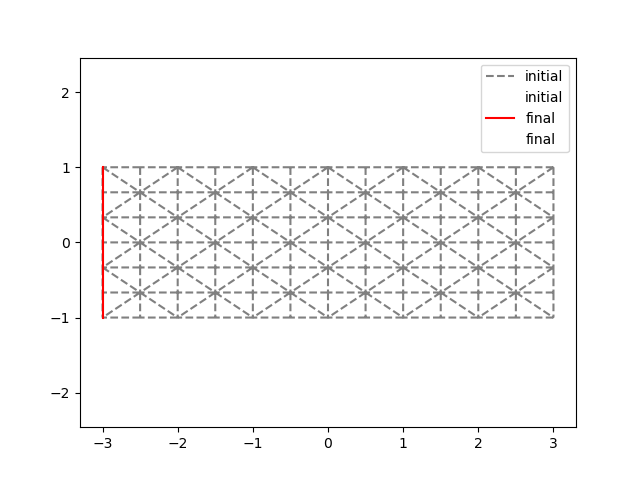

In [29]:
solve.plot_initial_vs_final()

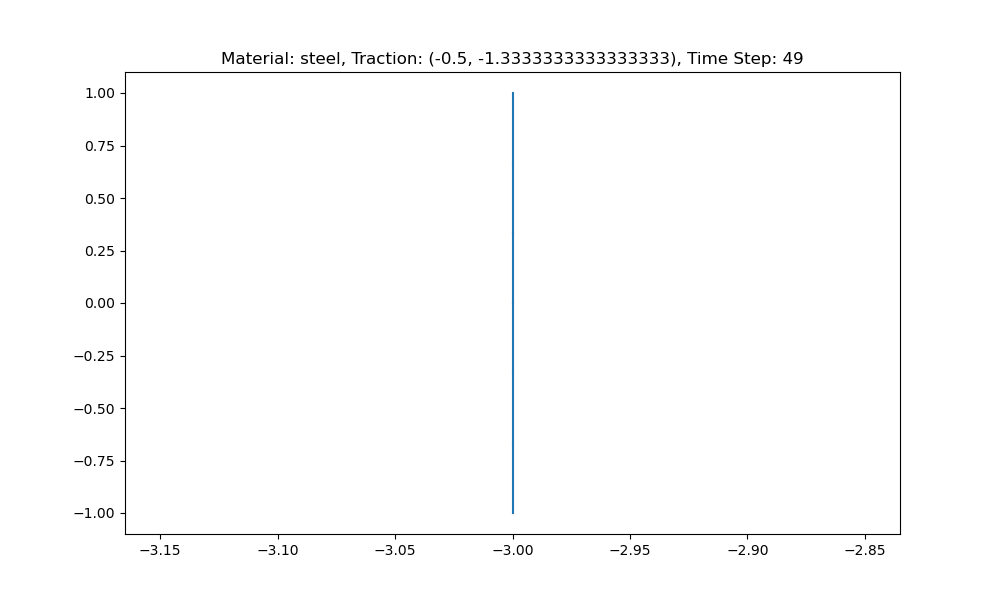

In [30]:
solve.animate()